# Global Wheat Detection: code walkthrough


In [ ]:
import json, shutil, subprocess, sys
from pathlib import Path

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

In [ ]:
DATA = next(p.parent for p in Path("/kaggle/input").rglob("train.csv"))
WORK, OUT = Path("/kaggle/working/yolo"), Path("/kaggle/working/results")
OUT.mkdir(parents=True, exist_ok=True)
IMG, EPOCHS, SEED = 1024, 40, 42

In [ ]:
df = pd.read_csv(DATA / "train.csv")
df[["x", "y", "w", "h"]] = np.array([json.loads(b) for b in df.bbox])
images = pd.DataFrame({"image_id": [p.stem for p in (DATA / "train").glob("*.jpg")]})
src = df.groupby("image_id").source.first()
images["source"] = images.image_id.map(src).fillna("no_boxes") 
tr_ids, va_ids = train_test_split(images.image_id, test_size=0.15, stratify=images.source, random_state=SEED)

In [ ]:
boxes = {k: g[["x", "y", "w", "h"]].to_numpy() for k, g in df.groupby("image_id")}
for split, ids in [("train", tr_ids), ("val", va_ids)]:
    (WORK / "images" / split).mkdir(parents=True, exist_ok=True)
    (WORK / "labels" / split).mkdir(parents=True, exist_ok=True)
    for i in ids:
        (WORK / "images" / split / f"{i}.jpg").symlink_to(DATA / "train" / f"{i}.jpg")
        b = boxes.get(i, np.zeros((0, 4)))
        lines = [f"0 {(x + w / 2) / 1024:.6f} {(y + h / 2) / 1024:.6f} {w / 1024:.6f} {h / 1024:.6f}" for x, y, w, h in b]
        (WORK / "labels" / split / f"{i}.txt").write_text("\n".join(lines))
(WORK / "wheat.yaml").write_text(f"path: {WORK}\ntrain: images/train\nval: images/val\nnames: {{0: wheat_head}}\n")

In [ ]:
try:
    model = YOLO("yolo26m.pt")
except Exception:
    model = YOLO("yolo11m.pt")
model.train(data=str(WORK / "wheat.yaml"), imgsz=IMG, epochs=EPOCHS, batch=8, seed=SEED, cos_lr=True,
            close_mosaic=8, flipud=0.5, fliplr=0.5, degrees=0, mixup=0.1, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,
            project=str(WORK / "runs"), name="wheat", exist_ok=True, plots=True, verbose=False)
best = YOLO(str(WORK / "runs/wheat/weights/best.pt"))

In [ ]:
def iou_matrix(a, b):  # boxes as x1 y1 x2 y2
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(2)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter)

In [ ]:
def image_precision(gt, pred):
    """Competition metric for one image; pred sorted by confidence."""
    if len(gt) == 0 and len(pred) == 0:
        return None  
    if len(gt) == 0 or len(pred) == 0:
        return 0.0
    ious = iou_matrix(pred, gt); out = []
    for t in np.arange(0.5, 0.76, 0.05):
        used, tp = set(), 0
        for p in range(len(pred)):
            cand = [(ious[p, g], g) for g in range(len(gt)) if g not in used and ious[p, g] >= t]
            if cand:
                used.add(max(cand)[1]); tp += 1
        fp, fn = len(pred) - tp, len(gt) - tp
        out.append(tp / (tp + fp + fn))
    return float(np.mean(out))

In [ ]:
def evaluate(conf, tta):
    rows = []
    for i in va_ids:
        r = best.predict(str(DATA / "train" / f"{i}.jpg"), imgsz=IMG, conf=conf, iou=0.6, augment=tta, verbose=False, max_det=300)[0]
        pr = r.boxes.xyxy.cpu().numpy()[np.argsort(-r.boxes.conf.cpu().numpy())]
        g = boxes.get(i, np.zeros((0, 4))); g = np.c_[g[:, :2], g[:, :2] + g[:, 2:]]
        s = image_precision(g, pr)
        if s is not None:
            rows.append((i, images.set_index("image_id").source[i], s))
    return pd.DataFrame(rows, columns=["image_id", "source", "score"])

In [ ]:
half_a, half_b = train_test_split(list(va_ids), test_size=0.5, random_state=SEED)
sweep = {}
for tta in [False, True]:
    for conf in [0.2, 0.3, 0.4, 0.5]:
        res = evaluate(conf, tta)
        sweep[(tta, conf)] = res
        print(f"tta={tta} conf={conf} mAP(all val)={res.score.mean():.4f}", flush=True)
pick = max(sweep, key=lambda k: sweep[k][sweep[k].image_id.isin(half_a)].score.mean())
final = sweep[pick]
report = {
    "model": Path(best.ckpt_path).name if hasattr(best, "ckpt_path") else "best.pt",
    "base_weights": model.model_name if hasattr(model, "model_name") else "yolo m",
    "image_size": IMG, "epochs": EPOCHS,
    "validation": f"{len(va_ids)} held-out images, stratified by source",
    "chosen": {"tta": pick[0], "conf": pick[1], "chosen_on": "first half of validation images"},
    "map_050_075_reported_half": round(final[final.image_id.isin(half_b)].score.mean(), 4),
    "map_050_075_all_val": round(final.score.mean(), 4),
    "per_source": final.groupby("source").score.agg(["mean", "count"]).round(4).to_dict("index"),
    "sweep_all_val": {f"tta={k[0]},conf={k[1]}": round(v.score.mean(), 4) for k, v in sweep.items()},
    "ultralytics_val_map50_95": round(float(best.val(data=str(WORK / "wheat.yaml"), imgsz=IMG, verbose=False).box.map), 4),
}
(OUT / "metrics.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

In [ ]:
shutil.copy(WORK / "runs/wheat/weights/best.pt", OUT / "best.pt")
for f in ["results.png", "PR_curve.png", "confusion_matrix.png", "val_batch0_pred.jpg", "val_batch0_labels.jpg"]:
    if (WORK / "runs/wheat" / f).exists():
        shutil.copy(WORK / "runs/wheat" / f, OUT / f)
shutil.rmtree(WORK / "images"); shutil.rmtree(WORK / "labels")

In [ ]:
import cv2

tiles = []
for p in sorted((DATA / "test").glob("*.jpg"))[:4]:
    img = cv2.imread(str(p))
    r = best.predict(img, imgsz=IMG, conf=0.4, iou=0.6, augment=True, verbose=False, max_det=300)[0]
    for x1, y1, x2, y2 in r.boxes.xyxy.cpu().numpy().astype(int):
        cv2.rectangle(img, (x1, y1), (x2, y2), (30, 192, 255), 3)
    cv2.putText(img, f"{len(r.boxes)} heads", (24, 72), cv2.FONT_HERSHEY_SIMPLEX, 2.2, (0, 0, 0), 10)
    cv2.putText(img, f"{len(r.boxes)} heads", (24, 72), cv2.FONT_HERSHEY_SIMPLEX, 2.2, (255, 255, 255), 4)
    tiles.append(cv2.resize(img, (640, 640)))
grid = np.vstack([np.hstack(tiles[:2]), np.hstack(tiles[2:4])])
cv2.imwrite(str(OUT / "test_predictions.jpg"), grid, [cv2.IMWRITE_JPEG_QUALITY, 88])
print("saved", grid.shape)

## 14. Results

| measure | value |
|---|---|
| **competition metric, half B (reported)** | **0.698** |
| competition metric, all 514 held-out photos | 0.694 |
| Ultralytics mAP50-95 | 0.576 |

Sweep on all 514 photos:

| setting | score |
|---|---|
| tta=False,conf=0.2 | 0.673 |
| tta=False,conf=0.3 | 0.688 |
| tta=False,conf=0.4 | 0.685 |
| tta=False,conf=0.5 | 0.671 |
| tta=True,conf=0.2 | 0.662 |
| tta=True,conf=0.3 | 0.686 |
| tta=True,conf=0.4 | 0.694 |
| tta=True,conf=0.5 | 0.690 |

The confidence cut-off matters more than TTA: 0.3 to 0.4 is the sweet spot, and 0.2 lets in too many
false boxes.

By research site:

| source | site | photos | score |
|---|---|---|---|
| rres_1 | Rothamsted Research, UK | 65 | 0.825 |
| inrae_1 | INRAE, France | 26 | 0.803 |
| ethz_1 | ETH Zurich, Switzerland | 112 | 0.758 |
| usask_1 | University of Saskatchewan, Canada | 30 | 0.690 |
| arvalis_3 | Arvalis, France | 84 | 0.689 |
| arvalis_1 | Arvalis, France | 159 | 0.619 |
| arvalis_2 | Arvalis, France | 31 | 0.502 |


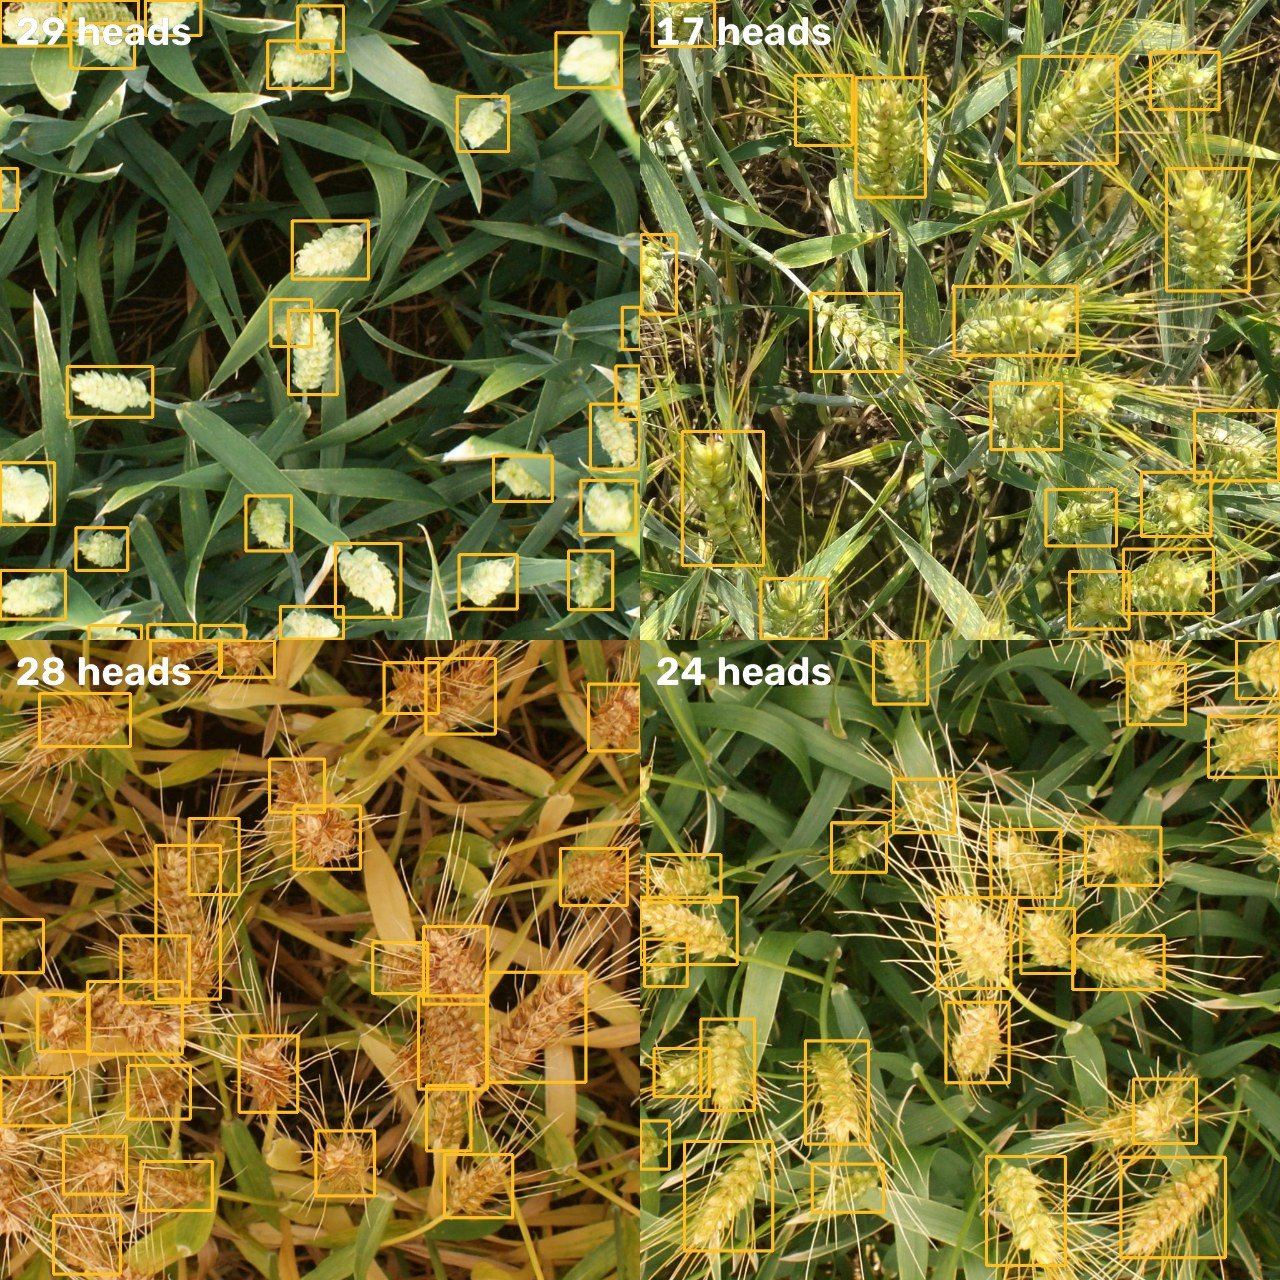

*Predicted wheat heads on four unseen competition test photos*

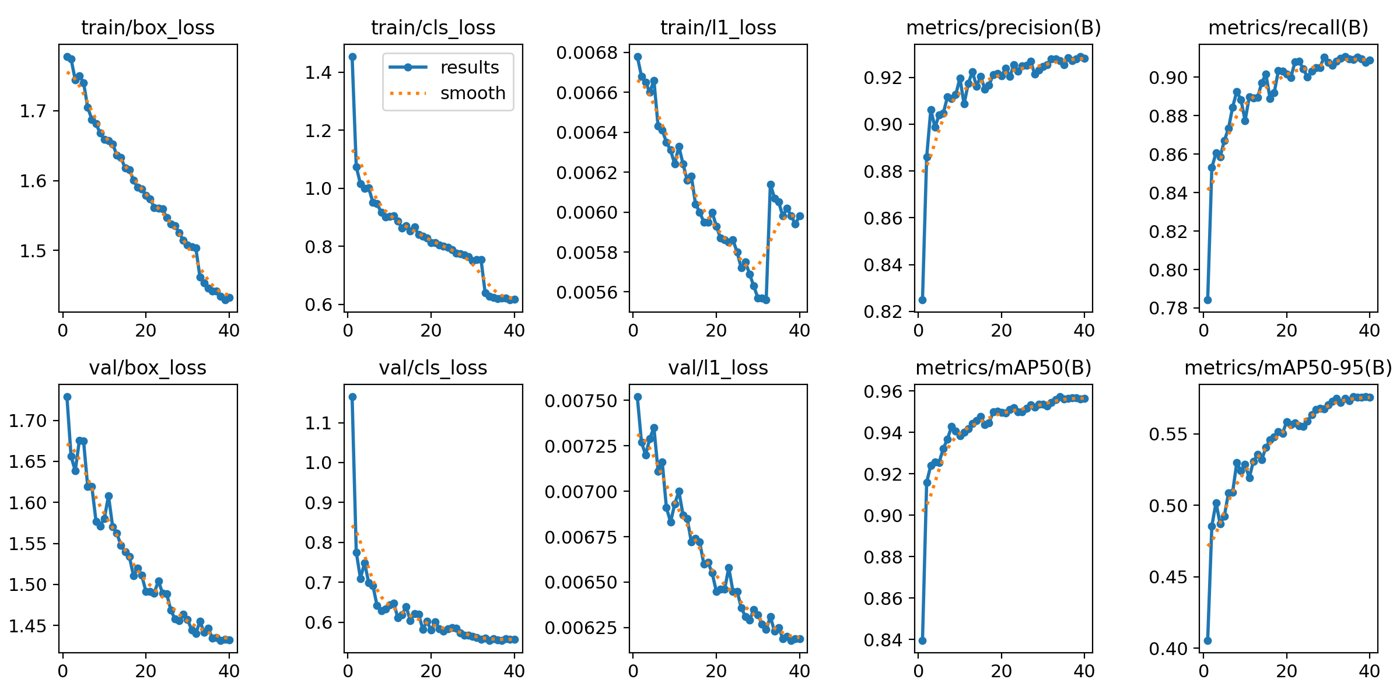

*Ultralytics training curves: losses and validation metrics per epoch*